# 7 – RAG with HiRAG

Notebooks 5 and 6 built two different hierarchies over the documents:

- **RAPTOR** (notebook 5) clusters the *chunks* by their embeddings and summarises every cluster. Its hierarchy follows meaning, but it knows nothing about the things the text talks about.
- **GraphRAG** (notebook 6) extracts the *entities* and their relationships into a knowledge graph and groups the entities into communities with the Leiden algorithm. Its hierarchy follows structure: who is connected to whom in the text.

**HiRAG** (Huang et al., 2025, [*HiRAG: Retrieval-Augmented Generation with Hierarchical Knowledge*](https://arxiv.org/abs/2503.10150), EMNLP 2025 Findings; code at [github.com/hhy-huang/HiRAG](https://github.com/hhy-huang/HiRAG)) combines the two. The paper names two weaknesses of graph-based RAG:

1. **Similar entities can be far apart in the graph.** A knowledge graph contains only the relationships the text states. Two loans in two different documents are alike, but no sentence connects them, so the graph doesn't either.
2. **Local and global knowledge don't connect.** Retrieval in the style of GraphRAG's local search hands the LLM the entities closest to the question (local knowledge) and the reports of their communities (global knowledge), but nothing tells it how the details relate to the overview.

HiRAG answers each weakness with one module:

| Module | What it does | Answers |
|---|---|---|
| **HiIndex** | Clusters the *entities* of the graph by embedding, the way RAPTOR clusters chunks, and lets an LLM create *summary entities* for every cluster: more general concepts, linked to the entities they summarise. Repeats one layer up, then runs Leiden on the resulting multi-layer graph. | weakness 1 |
| **HiRetrieval** | Gives the LLM three levels of context: the entities closest to the question (local), the reports of their communities (global), and the relations along the shortest paths that connect the communities' key entities (bridge). | weakness 2 |

```
INDEXING
  chunks ─ LLM: entities, then relations ─► base knowledge graph ················ layer 0
                                                 │  embed, cluster (UMAP + GMM)
                                                 ▼
                                    LLM: summary entities per cluster ·········· layer 1
                                                 │  repeat while the clustering still finds structure
                                                 ▼
                                           ... layer k ─► hierarchical knowledge graph
                                                                │  hierarchical Leiden, one LLM report per community
                                                                ▼
                                                        communities + reports
QUERYING
  question ─► top-n entities ─────────────────────────────────────────► local
                  │  their communities ─► reports ─────────────────────► global
                  │  key entities of each community, shortest paths ───► bridge
                  ▼
          local + global + bridge + source chunks ─► LLM ─► answer
```

This notebook builds HiRAG by hand, step by step, on the four documents of notebook 6, so that the two graph methods can be compared directly.

Indexing is LLM-heavy: two extraction calls per chunk, one call per cluster, one report per community. So, like notebook 6, this notebook uses **OpenAI's API**, with `gpt-4.1-mini` as the LLM and `text-embedding-3-small` for the embeddings. Building the index takes 85 LLM calls – about a minute with the API, for a few tens of cents; a 24B model on a laptop would need well over an hour. Everything goes through LangChain, so the `RAG_LLM` environment variable still switches the chat model (*Things to try* shows a fully local setup).

**Before you run it**

- Put your OpenAI key into `.env` in the project folder: `OPENAI_API_KEY=sk-...` (the same file notebook 6 uses).
- The index is cached in `hirag_index.json`; delete the file to build it again.

## Imports

New compared with the earlier notebooks:

- `init_embeddings` – the embedding counterpart of `init_chat_model`: `"openai:text-embedding-3-small"` gives an `OpenAIEmbeddings` object, `"ollama:embeddinggemma:300m"` an `OllamaEmbeddings` one.
- `networkx` – the knowledge graph, as in notebook 6, and its shortest paths for the bridge.
- `hierarchical_leiden` from `graspologic_native` – the Leiden implementation GraphRAG uses internally (notebook 6), and that HiRAG's reference code calls through the `graspologic` package. It is installed with GraphRAG; `requirements.txt` lists it explicitly.
- `umap`, `GaussianMixture`, `numpy` – RAPTOR's clustering, explained in notebooks 5 and 5a–5c.
- `BaseModel`, `Field` – structured output, as in notebook 2.
- `load_dotenv` – reads the OpenAI key from `.env`, as in notebook 6.
- `matplotlib`, `fill` – two figures, with wrapped labels; `Markdown` and `display` – to show the answers formatted, as in notebook 6.
- `Counter`, `json`, `re` and `time` from the standard library.

In [1]:
import json
import os
import re
import time
from collections import Counter
from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import umap
from dotenv import load_dotenv
from graspologic_native import hierarchical_leiden
from IPython.display import Markdown, display
from langchain.chat_models import init_chat_model
from langchain.embeddings import init_embeddings
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_text_splitters import RecursiveCharacterTextSplitter
from pydantic import BaseModel, Field
from sklearn.mixture import GaussianMixture

## Configuration

- `CACHE_FILE` – the index is saved here stage by stage: the extracted entities and relations, the summary layers, and the communities with their reports. Delete it to rebuild, for example after changing a prompt, the chunking or the LLM.
- `LLM_MODEL`, `EMBEDDING_MODEL` – the models of notebook 6. `load_dotenv(".env")` puts `OPENAI_API_KEY` into the environment, where LangChain's OpenAI classes look for it; the key never appears in the notebook.
- `DOCUMENTS` – the four files and their titles, as in notebook 6. The title goes to the LLM with every chunk, so that "the Company" can be resolved to a name.
- `CHUNK_SIZE = 2000`, `CHUNK_OVERLAP = 200` – characters. HiRAG's code uses 1,200-token chunks (about 4,800 characters) with 100 tokens of overlap; smaller chunks make the extraction more thorough (notebook 6, *Things to try* 2).
- `ENTITY_TYPES` – what the extraction looks for: the general types of notebook 6, plus the things that financial statements and policies are made of – financial items, metrics, policies.
- `META_TYPES` – the categories the summary entities must belong to; see step 3.
- `UMAP_NEIGHBORS = 15`, `MAX_CLUSTERS = 50`, `CLUSTER_THRESHOLD = 0.1` – the clustering settings of HiRAG's code: UMAP to two dimensions with 15 neighbours, at most 50 Gaussian components, soft membership above 0.1 (RAPTOR's value).
- `SPARSITY_CHANGE = 0.05`, `MIN_LAYER_SIZE = 4` – when to stop adding layers; see step 3.
- `MAX_COMMUNITY_SIZE = 10` – Leiden splits communities with more entities than this again, as in notebook 6. `MAX_REPORT_INPUT = 12000` – at most this many characters of a community's entities and relations go to the report LLM.
- Retrieval (step 5): `TOP_N = 20` local entities per question, the paper's *n*. `TOP_M = 2` key entities per community for the bridge, the paper's *m*; HiRAG's code uses 10, sized for graphs with thousands of entities. `COMMUNITY_LEVEL = 2` – the deepest community level used, as in HiRAG's code and notebook 6. `REPORT_BUDGET = 20000` characters of community reports per question (HiRAG's code: 12,500 tokens). `MAX_BRIDGE = 30` relations from the paths, `TOP_SOURCES = 3` source chunks.
- `SEED` – for UMAP, Leiden and the graph layouts.

In [2]:
DATA_DIR = Path("data")
CACHE_FILE = Path("hirag_index.json")

load_dotenv(".env")
LLM_MODEL = os.getenv("RAG_LLM", "openai:gpt-4.1-mini")
EMBEDDING_MODEL = "openai:text-embedding-3-small"

DOCUMENTS = {
    "document_a.md": "The Employer Group, Inc. - Financial Statements 2019 and 2018",
    "novaterra_annual_report.txt": "Novaterra Energy AG - Annual Report 2025",
    "meridian_credit_policy.txt": "Meridian Bank - Retail Credit Policy 7.2",
    "harbor_city_transit.txt": "Harbor City Transit Authority - Annual Service Review 2025",
}
CHUNK_SIZE = 2000
CHUNK_OVERLAP = 200

ENTITY_TYPES = ["organization", "person", "location", "event", "asset", "product or service",
                "financial item", "metric", "policy", "technology"]
META_TYPES = ["industry", "business activity", "financial concept", "asset class", "risk",
              "regulation", "technology", "public service"]

UMAP_NEIGHBORS = 15
MAX_CLUSTERS = 50
CLUSTER_THRESHOLD = 0.1
SPARSITY_CHANGE = 0.05
MIN_LAYER_SIZE = 4

MAX_COMMUNITY_SIZE = 10
MAX_REPORT_INPUT = 12000

TOP_N = 20
TOP_M = 2
COMMUNITY_LEVEL = 2
REPORT_BUDGET = 20000
MAX_BRIDGE = 30
TOP_SOURCES = 3

SEED = 7

print("LLM:", LLM_MODEL)

LLM: openai:gpt-4.1-mini


## Step 1 – LOAD and CHUNK

The four documents of notebook 6. The financial statements get the clean-up of notebooks 5 and 6: escaped dollar signs are restored and the `---` rules removed. Every document carries its title and the name of its organisation – the part of the title before " - " – in the metadata. The organisation lets us see later which documents an entity comes from.

The splitter is notebook 5's: the recursive splitter with an extra separator after every HTML table row, so that long tables are cut between rows. Every chunk gets a `chunk_id` (`C0`, `C1`, …) that the entities will point back to.

In [3]:
docs = []
for file_name, title in DOCUMENTS.items():
    text = (DATA_DIR / file_name).read_text(encoding="utf-8").replace("\\$", "$")
    text = "\n".join(line for line in text.splitlines() if line.strip() != "---")
    docs.append(Document(page_content=text,
                         metadata={"title": title, "organisation": title.split(" - ")[0]}))

splitter = RecursiveCharacterTextSplitter(
    chunk_size=CHUNK_SIZE,
    chunk_overlap=CHUNK_OVERLAP,
    separators=["\n\n", "\n", r"(?<=</tr>)", r"(?<=\. )", " ", ""],
    is_separator_regex=True,
)
chunks = splitter.split_documents(docs)
for i, chunk in enumerate(chunks):
    chunk.metadata["chunk_id"] = f"C{i}"
chunk_by_id = {c.metadata["chunk_id"]: c for c in chunks}

print(f"{len(docs)} documents -> {len(chunks)} chunks")
for organisation, count in Counter(c.metadata["organisation"] for c in chunks).items():
    print(f"  {count:2d}  {organisation}")

4 documents -> 19 chunks
  14  The Employer Group, Inc.
   2  Novaterra Energy AG
   2  Meridian Bank
   1  Harbor City Transit Authority


## Step 2 – The base knowledge graph (layer 0)

### Entities first, then relations

The paper builds the base graph in two passes, following Carta et al. (2023): first the LLM lists the entities of a chunk, then a second call relates the entities it found. GraphRAG asks for both in a single call. We use structured output, as in notebook 2, instead of the reference code's delimited text format: LangChain turns the Pydantic models into a JSON schema and the model's answer back into Python objects.

- `Entity` – name, type and description, the fields of GraphRAG's and HiRAG's prompts. `Entities` is what the first call returns.
- `Relation` – source, target, description and a strength from 1 to 10, which becomes the weight of the edge. `Relations` is what the second call returns.

Both prompts get the document title and ask the model to resolve "the Company" to the full name – the lesson of notebooks 2 and 6. Two more details came out of testing on our documents:

- The entity prompt says what counts as an entity – anything specific the text states facts about – and asks for the items in tables. A first version that only listed the types got little more than the company itself out of most chunks of the financial statements: about a third of the entities found now.
- The relation prompt lists the chunk's entities and asks for their names exactly. A relation to any other name is dropped when the graph is built.

HiRAG's code, like GraphRAG, adds *gleaning* rounds that ask the model for entities it missed; we leave them out.

In [4]:
class Entity(BaseModel):
    name: str = Field(description="Name of the entity, in capital letters")
    type: str = Field(description="One of the given entity types")
    description: str = Field(description="Comprehensive description of the entity's attributes and activities")


class Entities(BaseModel):
    entities: list[Entity]


class Relation(BaseModel):
    source: str = Field(description="Name of the source entity, exactly as in the entity list")
    target: str = Field(description="Name of the target entity, exactly as in the entity list")
    description: str = Field(description="Why the source entity and the target entity are related")
    strength: int = Field(description="Strength of the relationship, from 1 (weak) to 10 (strong)")


class Relations(BaseModel):
    relations: list[Relation]


ENTITY_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "Identify all entities in the text, of these types: {entity_types}. An entity is anything "
     "specific the text states facts about - an organisation, a role, a place, an asset, a loan, "
     "a lease, a revenue or cost item, a ratio, a rule. Be exhaustive and include the items in "
     "tables. For each entity give its name in capital letters, its type, and a comprehensive "
     "description of its attributes and activities, with figures, dates, rates and conditions "
     "exactly as stated. The document title tells you who the text is about: resolve references "
     "such as 'the Company', 'the bank' or 'it' to the full name. Use only information from the "
     "text."),
    ("human", "Document title: {title}\n\nText:\n{text}"),
])

RELATION_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "You get a text and the entities that were identified in it. Identify all pairs of these "
     "entities that are clearly related to each other, using the entity names exactly as listed. "
     "For each pair explain why the two are related, with figures as stated, and rate the "
     "strength of the relationship from 1 to 10."),
    ("human", "Document title: {title}\n\nEntities: {entities}\n\nText:\n{text}"),
])

### Running the extraction

Two `.batch()` runs, as in notebook 2: all entity extractions, then all relation extractions, each with up to eight requests in parallel. The second run needs the entity names of the first.

The results go into the dictionary `index` under the key `"extraction"`, which is written to `CACHE_FILE`; the later stages add their own keys to the same file. When the file exists, it is loaded and every stage that is already in it is skipped. `llm` and `embeddings` are created here because every stage needs them.

In [5]:
index = json.loads(CACHE_FILE.read_text()) if CACHE_FILE.exists() else {}
llm = init_chat_model(LLM_MODEL, temperature=0)
embeddings = init_embeddings(EMBEDDING_MODEL)

if "extraction" in index:
    print(f"Using cached extraction from {CACHE_FILE.name}")
else:
    start = time.time()
    entity_chain = ENTITY_PROMPT | llm.with_structured_output(Entities)
    relation_chain = RELATION_PROMPT | llm.with_structured_output(Relations)
    found = entity_chain.batch(
        [{"entity_types": ", ".join(ENTITY_TYPES), "title": c.metadata["title"], "text": c.page_content}
         for c in chunks],
        config={"max_concurrency": 8},
    )
    related = relation_chain.batch(
        [{"title": c.metadata["title"], "entities": ", ".join(e.name for e in f.entities),
          "text": c.page_content}
         for c, f in zip(chunks, found)],
        config={"max_concurrency": 8},
    )
    index["extraction"] = [
        {"chunk_id": c.metadata["chunk_id"],
         "entities": [e.model_dump() for e in f.entities],
         "relations": [r.model_dump() for r in rel.relations]}
        for c, f, rel in zip(chunks, found, related)
    ]
    CACHE_FILE.write_text(json.dumps(index, indent=1))
    print(f"{2 * len(chunks)} LLM calls in {time.time() - start:.0f} s")

print(f"{sum(len(x['entities']) for x in index['extraction'])} entity mentions and "
      f"{sum(len(x['relations']) for x in index['extraction'])} relations from {len(index['extraction'])} chunks")

38 LLM calls in 28 s
177 entity mentions and 173 relations from 19 chunks


### From mentions to a graph

The same entity is often mentioned in several chunks, and, as in GraphRAG, mentions are merged by name. `build_base_graph` turns the extraction into a `networkx` graph:

- Names are stripped and upper-cased, so that "Bank" and "BANK" become one node.
- A node collects the types, descriptions, chunks and organisations of all its mentions. Afterwards its type is the most frequent one and its description the distinct descriptions joined together. GraphRAG and HiRAG's code let an LLM condense long merged descriptions; we keep them as they are.
- `add_relation` adds an edge, or, if the two entities are already connected, adds the strength to the edge's weight and appends the description. The graph is undirected, as in HiRAG's code.
- A relation whose source or target is not an entity of the same chunk is dropped and counted.

Every node gets `layer = 0`: the base graph is the bottom layer of the hierarchy. The printout lists the connected components and the organisations each one covers, and the entities that more than one organisation shares.

In [6]:
def add_relation(graph, source, target, description, strength):
    if graph.has_edge(source, target):
        edge = graph.edges[source, target]
        edge["weight"] += strength
        edge["description"] += " " + description
    else:
        graph.add_edge(source, target, weight=strength, description=description)


def build_base_graph(extraction):
    graph, dropped = nx.Graph(), 0
    for item in extraction:
        organisation = chunk_by_id[item["chunk_id"]].metadata["organisation"]
        names = set()
        for e in item["entities"]:
            name = e["name"].strip().upper()
            if name not in graph:
                graph.add_node(name, layer=0, types=[], descriptions=[], chunks=[], organisations=[])
            node = graph.nodes[name]
            node["types"].append(e["type"].lower())
            node["descriptions"].append(e["description"])
            node["chunks"].append(item["chunk_id"])
            node["organisations"].append(organisation)
            names.add(name)
        for r in item["relations"]:
            source, target = r["source"].strip().upper(), r["target"].strip().upper()
            if source == target or source not in names or target not in names:
                dropped += 1
                continue
            add_relation(graph, source, target, r["description"], r["strength"])
    for node in graph.nodes.values():
        node["type"] = Counter(node.pop("types")).most_common(1)[0][0]
        node["description"] = " ".join(dict.fromkeys(node.pop("descriptions")))
        node["chunks"] = list(dict.fromkeys(node["chunks"]))
        node["organisations"] = sorted(set(node["organisations"]))
    return graph, dropped


def show_components(graph):
    for component in sorted(nx.connected_components(graph), key=len, reverse=True):
        organisations = sorted(set().union(*(graph.nodes[n]["organisations"] for n in component)))
        print(f"  {len(component):4d} entities: {', '.join(organisations)}")


base_graph, dropped = build_base_graph(index["extraction"])
print(f"{base_graph.number_of_nodes()} entities and {base_graph.number_of_edges()} relations "
      f"({dropped} relations dropped)\n")
print(f"{nx.number_connected_components(base_graph)} connected components:")
show_components(base_graph)
shared = [n for n, d in base_graph.nodes(data=True) if len(d["organisations"]) > 1]
print("\nentities of more than one organisation:", ", ".join(shared))

143 entities and 165 relations (0 relations dropped)

4 connected components:
   115 entities: Novaterra Energy AG, The Employer Group, Inc.
    13 entities: Meridian Bank
     8 entities: Harbor City Transit Authority
     7 entities: Harbor City Transit Authority

entities of more than one organisation: NET INCOME, REVENUE


The base graph has the shape notebook 6 found: one hub per document, with most entities attached directly to their organisation. The 177 mentions became 143 entities, and no relation had to be dropped. There are four connected components, but not one per document:

- The Employer Group and Novaterra share a component only through NET INCOME and REVENUE. Both documents mention these generic entities, so they were merged by name – a link between two unrelated companies that no sentence states.
- Harbor City falls apart into two components: the authority and its network on one side, the budget and the fares on the other. The relation pass found nothing that connects the two halves of the text.

This is weakness 1 in its plainest form. Entities that belong together – Harbor City's fares and its network, or Meridian's debt-service ratio and Novaterra's leverage ratio – are not connected, or only through a coincidence of names.

## Step 3 – HiIndex: the summary layers

To build layer *i*, HiRAG embeds the entities of layer *i* − 1, clusters them with RAPTOR's method, and asks an LLM to summarise every cluster with one or more *summary entities*. Each summary entity is linked to the entities it covers. The summary entities form layer *i*, and the process repeats on them. Summary entities of the same layer are not linked to each other, only to their members below. Layer by layer, the graph gets more general concepts on top of the specific ones, and entities that share a concept get a common neighbour.

### Clustering one layer

`cluster_entities(vectors)` follows HiRAG's code, which follows RAPTOR (notebooks 5 and 5a–5c explain each step):

1. **UMAP** to two dimensions, with 15 neighbours and cosine distance. In two dimensions UMAP keeps neighbourhoods far better than PCA (notebook 5a), and a two-dimensional Gaussian has only six parameters, so BIC works with clusters of a dozen entities (notebook 5c). With a seed, UMAP runs on a single thread anyway; `n_jobs=1` says so and avoids a warning.
2. **A Gaussian mixture** for every number of components *K* up to `MAX_CLUSTERS`, and at most a third of the number of entities – notebook 5's cap. The lowest BIC wins. Without the cap, BIC on a layer of about 30 summary entities picks the largest *K* it is offered, with two entities per cluster: the degenerate regime of notebook 5c.
3. **Soft membership:** an entity joins every cluster in which its probability exceeds `CLUSTER_THRESHOLD`.

`cluster_sparsity(clusters, n)` is the paper's measure of how well a layer clusters, its equation 17:

$$CS = 1 - \frac{\sum_{S} |S|\,(|S| - 1)}{n\,(n - 1)}$$

It is the share of pairs of entities that do *not* share a cluster: 0 when everything is in one cluster, 1 when every entity is alone. The paper stops adding layers when *CS* changes by less than 5 percent from one layer to the next, because then the clustering has stopped finding new structure.

In [7]:
def cluster_entities(vectors):
    n = len(vectors)
    X = umap.UMAP(n_neighbors=min(UMAP_NEIGHBORS, n - 1), n_components=2, metric="cosine",
                  random_state=SEED, n_jobs=1).fit_transform(np.array(vectors))
    max_k = max(1, min(MAX_CLUSTERS, n // 3))
    models = [GaussianMixture(k, n_init=5, random_state=0).fit(X) for k in range(1, max_k + 1)]
    best = min(models, key=lambda m: m.bic(X))
    probabilities = best.predict_proba(X)
    clusters = [list(np.where(probabilities[:, c] > CLUSTER_THRESHOLD)[0]) for c in range(best.n_components)]
    return [c for c in clusters if c]


def cluster_sparsity(clusters, n):
    return 1 - sum(len(c) * (len(c) - 1) for c in clusters) / (n * (n - 1))

### Summary entities

The paper guides the summarisation with *meta summary entities*: a small set of general categories, and every summary entity must be of one of them. HiRAG's code ships the list organization, person, location, event, product, technology, industry, mathematics, social sciences.

Three changes were necessary for our documents, each one found while developing this notebook:

- **No organisations among the meta types.** With `organization` in the list – and the reference prompt's example, which summarises Instagram, Facebook and WhatsApp by META – the model summarised most clusters by the company the entities belong to. That company already exists as an entity, so the layer added nothing. `META_TYPES` therefore lists business categories, and the prompt uses the paper's own example instead: BIG DATA and RECOMMENDATION SYSTEM are summarised by DATA MINING.
- **General descriptions.** A summary entity is described as a concept, without the organisations or figures of its members, as in the reference prompt's example; the specifics go into the links. This matters for the next layer. Descriptions that named the organisation made the next clustering group by organisation again, while general ones let concepts from different documents meet.
- **Each summary entity lists its members.** In the reference prompt the LLM returns the summary entities and, separately, a list of links. With that flat format and a group of 30 entities, `gpt-4.1-mini` often produced one "summary" per entity under a slightly changed name. In `ClusterSummary`, every summary entity carries its own list of `members`, which must have at least two entries. `valid_summaries` drops any summary entity that still covers fewer than two entities of its cluster: a summary of a single entity connects nothing.

For each member, the model explains why it belongs to the summary entity and rates the strength; these become the description and the weight of the link.

In [8]:
class Member(BaseModel):
    name: str = Field(description="Name of one of the given entities, exactly as given")
    description: str = Field(description="Why this entity belongs to the summary entity, with the names and figures from its description")
    strength: int = Field(description="Strength of the relationship, from 1 (weak) to 10 (strong)")


class SummaryEntity(BaseModel):
    name: str = Field(description="Name of the summary entity, in capital letters")
    type: str = Field(description="One of the meta types")
    description: str = Field(description="Two or three sentences describing the summary entity as a general concept, without naming organisations or figures")
    members: list[Member] = Field(description="The given entities that this summary entity covers: at least two, usually more")


class ClusterSummary(BaseModel):
    summary_entities: list[SummaryEntity]


SUMMARY_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "You get a group of entities from a knowledge graph with their descriptions, and a list of "
     "meta types: {meta_types}. Summarise the group with summary entities: more general concepts "
     "that several of the given entities are instances, parts or aspects of. Each summary entity "
     "is a specific concept of one of the meta types, not the meta type itself: BIG DATA and "
     "RECOMMENDATION SYSTEM are both summarised by DATA MINING, a concept of type technology. It "
     "covers at least two of the given entities, also across different organisations, and it "
     "must not be one of them nor the organisation they belong to. Create one summary entity per "
     "theme that the given entities share - one for a small group, several for a large one. "
     "Describe each summary entity as a general concept. List the given entities that each "
     "summary entity covers; for each, explain why it belongs there and rate the strength of the "
     "relationship from 1 to 10. Use the given entity names exactly."),
    ("human", "Entities:\n{entities}"),
])


def valid_summaries(result, cluster):
    kept = []
    for s in result.summary_entities:
        name = s.name.strip().upper()
        members = [m for m in s.members if m.name.strip().upper() in cluster and m.name.strip().upper() != name]
        if len(members) >= 2:
            kept.append({"name": name, "type": s.type.lower(), "description": s.description,
                         "members": [{"name": m.name.strip().upper(), "description": m.description,
                                      "strength": m.strength} for m in members]})
    return kept

### Building the layers

`build_layers(descriptions)` is the paper's Algorithm 1. `current` maps the names of the entities that are about to be clustered to their descriptions; it starts with the base graph. Every round:

1. Embeds `current` as `NAME: description` and clusters it, then computes the cluster sparsity and its change against the previous round.
2. Stops if the change is at most `SPARSITY_CHANGE`.
3. Summarises every cluster of two or more entities, all clusters in one `.batch()`.
4. Makes the new summary entities the next layer, together with the entities that were alone in their cluster; those are carried up unchanged, as in HiRAG's code.

Two more stopping rules. A layer of `MIN_LAYER_SIZE` entities or fewer is not clustered (HiRAG's code stops at two). And after a layer that was clustered as a single group, we stop: that layer has been summarised as a whole, like the root in notebook 5, and there is nothing above it to group. Without this rule the next sparsity would be compared with 0, and any change looks infinite.

The LLM calls are the expensive part, so the layers are cached under `"layers"`: for each layer its clusters and its valid summary entities. The graph is built from them in the next cell.

In [9]:
def build_layers(descriptions):
    summary_chain = SUMMARY_PROMPT | llm.with_structured_output(ClusterSummary)
    layers, current, previous = [], dict(descriptions), None
    while len(current) > MIN_LAYER_SIZE:
        names = list(current)
        vectors = embeddings.embed_documents([f"{n}: {current[n]}" for n in names])
        clusters = [[names[i] for i in members] for members in cluster_entities(vectors)]
        sparsity = cluster_sparsity(clusters, len(names))
        change = None if previous is None else abs(sparsity - previous) / (previous + 1e-8)
        print(f"layer {len(layers)}: {len(names)} entities -> {len(clusters)} clusters of sizes "
              f"{sorted((len(c) for c in clusters), reverse=True)}, cluster sparsity {sparsity:.3f}"
              + ("" if change is None else f" (change {change:.1%})"))
        if change is not None and change <= SPARSITY_CHANGE:
            print("   change below the threshold: stop")
            break
        groups = [c for c in clusters if len(c) > 1]
        results = summary_chain.batch(
            [{"meta_types": ", ".join(META_TYPES), "entities": "\n".join(f"- {n}: {current[n]}" for n in g)}
             for g in groups],
            config={"max_concurrency": 8},
        )
        summaries = [s for g, r in zip(groups, results) for s in valid_summaries(r, set(g))]
        print(f"   {len(groups)} LLM calls -> {len(summaries)} summary entities for layer {len(layers) + 1}")
        layers.append({"clusters": clusters, "summaries": summaries})
        upper = {s["name"]: s["description"] for s in summaries}
        for c in clusters:
            if len(c) == 1:
                upper.setdefault(c[0], current[c[0]])
        current = upper
        if len(clusters) == 1:
            print("   the layer was summarised as a single group: stop")
            break
        previous = sparsity
    return layers


if "layers" in index:
    print(f"Using cached layers from {CACHE_FILE.name}")
else:
    start = time.time()
    index["layers"] = build_layers({n: d["description"] for n, d in base_graph.nodes(data=True)})
    CACHE_FILE.write_text(json.dumps(index, indent=1))
    print(f"built in {time.time() - start:.0f} s")

layer 0: 143 entities -> 8 clusters of sizes [41, 27, 21, 18, 16, 15, 13, 6], cluster sparsity 0.818


   8 LLM calls -> 28 summary entities for layer 1


layer 1: 28 entities -> 1 clusters of sizes [28], cluster sparsity 0.000 (change 100.0%)


   1 LLM calls -> 5 summary entities for layer 2
   the layer was summarised as a single group: stop
built in 21 s


### The hierarchical graph

The layers are applied to a copy of the base graph. Every summary entity becomes a node with its layer number, and every member gets a link to it through `add_relation`, so a pair that is already connected gets the strength added. A summary entity whose name already exists – for example a concept that two clusters both produced – is merged into the existing node and keeps the first description. Summary entities have no chunks. Their `organisations` are those of the entities below them, which shows which documents a summary entity connects.

The printout goes top-down: every summary entity with the organisations it covers and its members.

In [10]:
graph = base_graph.copy()
for number, layer in enumerate(index["layers"], 1):
    for s in layer["summaries"]:
        if s["name"] not in graph:
            graph.add_node(s["name"], layer=number, type=s["type"], description=s["description"],
                           chunks=[], organisations=[])
        for m in s["members"]:
            add_relation(graph, m["name"], s["name"], m["description"], m["strength"])
    for name, node in graph.nodes(data=True):
        if node["layer"] == number:
            node["organisations"] = sorted(set().union(*(
                graph.nodes[m]["organisations"] for m in graph.neighbors(name) if graph.nodes[m]["layer"] < number)))

layer_sizes = Counter(d["layer"] for _, d in graph.nodes(data=True))
print(f"{graph.number_of_nodes()} entities and {graph.number_of_edges()} relations; "
      f"entities per layer: {dict(sorted(layer_sizes.items()))}")
for number in range(max(layer_sizes), 0, -1):
    print(f"\n=== layer {number} ===")
    for name, node in graph.nodes(data=True):
        if node["layer"] == number:
            members = [m for m in graph.neighbors(name) if graph.nodes[m]["layer"] < number]
            print(f"{name} ({node['type']}; {', '.join(node['organisations'])})")
            print(fill(", ".join(members), 110, initial_indent="    <- ", subsequent_indent="       "))

175 entities and 304 relations; entities per layer: {0: 143, 1: 27, 2: 5}

=== layer 2 ===
PUBLIC TRANSPORTATION SYSTEMS (public service; Harbor City Transit Authority)
    <- PUBLIC TRANSPORTATION NETWORKS, SUSTAINABLE TRANSPORT TECHNOLOGY, PUBLIC TRANSPORT FUNDING MODELS, FARE
       STRUCTURE AND POLICY, TRANSIT SERVICE PERFORMANCE MANAGEMENT
FINANCIAL REPORTING AND ACCOUNTING (financial concept; Novaterra Energy AG, The Employer Group, Inc.)
    <- FINANCIAL REPORTING, CURRENT ASSETS, CURRENT LIABILITIES, LONG-TERM LIABILITIES, ACCOUNTS RECEIVABLE,
       CAPITAL LEASES, REVENUE AND EXPENSE ACCOUNTS, CASH FLOW ITEMS, TAXATION AND COMPLIANCE, EMPLOYEE
       BENEFITS AND COMPENSATION, ASSET MANAGEMENT, LEASE ACCOUNTING
FINANCIAL INSTRUMENTS AND RISK MANAGEMENT (financial concept; The Employer Group, Inc.)
    <- DEBT INSTRUMENTS, FINANCIAL RISK MANAGEMENT
RENEWABLE ENERGY AND UTILITY OPERATIONS (industry; Novaterra Energy AG)
    <- RENEWABLE ENERGY GENERATION, ENERGY UTILITY OPERAT

Read the layers bottom-up. The eight clusters of layer 0 produced 28 summary entities; one of them, ACCOUNTS RECEIVABLE, already existed as an entity of the financial statements and was merged into it, so layer 1 has 27 new entities. They are good concepts, and many gather entities that the text connects only through their company: CREDIT RISK MANAGEMENT gathers Meridian's policy, score, DSTI and delinquency rate; LEASE ACCOUNTING the Employer Group's capital and operating leases; GEOGRAPHIC LOCATION Linz, Austria, Central Europe and Lower Austria. On the 28 entities of layer 1, BIC found no evidence for more than one cluster, so one LLM call summarised them all into the five entities of layer 2, and the build stopped. Layer 2 has one concept per organisation, and two for the Employer Group.

Two summary entities list two organisations, FINANCIAL PERFORMANCE METRICS and FINANCIAL REPORTING AND ACCOUNTING. Neither joins two documents on its own: each covers entities of one company plus REVENUE or NET INCOME, the generic entities the base graph already shared. On four documents about four unrelated organisations, the summary layers stayed inside the organisations. Every cluster of layer 0 held the entities of a single document (plus, in two of them, one of the shared entities), because every description names its organisation; and the single summary call at the top grouped by organisation as well. While developing this notebook, some runs produced a summary entity that joined the Employer Group's bank loans with Meridian's lending, but never reliably. The paper's corpora are different: hundreds of documents from one domain, whose entities share topics across documents.

### Did similar entities come closer?

Weakness 1, measured on our graph. For every base entity we take the five base entities most similar to it by embedding – the pairs a reader would call related – and count the hops between each pair, in the flat and in the hierarchical graph. `vectors @ vectors.T` is the matrix of cosine similarities, because OpenAI's embeddings have unit length; the diagonal is set to −1 so that an entity is not its own neighbour.

In [11]:
base_names = list(base_graph.nodes)
vectors = np.array(embeddings.embed_documents([f"{n}: {base_graph.nodes[n]['description']}" for n in base_names]))
similarity = vectors @ vectors.T
np.fill_diagonal(similarity, -1)
pairs = {tuple(sorted((base_names[i], base_names[j])))
         for i in range(len(base_names)) for j in np.argsort(-similarity[i])[:5]}

print(f"{len(pairs)} pairs of similar entities, by number of hops between them:")
for label, g in (("flat", base_graph), ("hierarchical", graph)):
    hops = Counter(nx.shortest_path_length(g, a, b) if nx.has_path(g, a, b) else None for a, b in pairs)
    counts = [f"{k} hops: {hops[k]}" for k in sorted(k for k in hops if k is not None)]
    print(f"  {label:12} {', '.join(counts)}, not connected: {hops[None]}")

print(f"\nconnected components of the hierarchical graph ({nx.number_connected_components(graph)}):")
show_components(graph)

501 pairs of similar entities, by number of hops between them:
  flat         1 hops: 77, 2 hops: 358, 3 hops: 39, 4 hops: 4, not connected: 23
  hierarchical 1 hops: 79, 2 hops: 372, 3 hops: 27, 4 hops: 6, 5 hops: 12, not connected: 5

connected components of the hierarchical graph (3):
   137 entities: Novaterra Energy AG, The Employer Group, Inc.
    21 entities: Harbor City Transit Authority
    17 entities: Meridian Bank


Most similar pairs – 358 of 501 – were already two hops apart in the flat graph: both entities hang off the same company hub. The summary entities changed the rest in two ways:

- **Shortcuts within a document.** Sixteen pairs that were three or four hops apart are now two hops apart. DSTI and the 90-day delinquency rate meet at CREDIT RISK MANAGEMENT, Linz and Lower Austria at GEOGRAPHIC LOCATION, the leased office equipment and the office lease at LEASE ACCOUNTING – the paper's BIG DATA and RECOMMENDATION SYSTEM meeting at DATA MINING, on a small scale.
- **Connections the text did not make.** Clustering put both halves of Harbor City into one cluster, and the summary entities joined them: the graph has three components now. CITY SUBSIDY and FERRY ROUTES, unconnected before, are four hops apart, via PUBLIC TRANSPORT FUNDING MODELS, PUBLIC TRANSPORTATION SYSTEMS (layer 2) and PUBLIC TRANSPORTATION NETWORKS. 18 of the 23 unconnected pairs were joined like this, up and down the hierarchy.

The five pairs that remain unconnected are the instructive ones: all are similar entities of *different* organisations – Meridian's DSTI next to Novaterra's leverage ratio and net debt, Meridian's 90-day delinquency rate next to the Employer Group's receivables and its LIBOR rate, Harbor City's planned bus lanes next to Novaterra's permitting delays. These are exactly the pairs HiRAG is designed to connect, and our summary layers, which stayed inside the organisations, did not.

## Step 4 – Communities and reports

HiRAG runs Leiden on the hierarchical graph, as GraphRAG does on the flat one (notebook 6 explains the algorithm and its levels). The paper argues that the summary entities change what Leiden finds: they act as *semantic hubs*, so the communities follow shared concepts as well as the relations the text states. That is easy to check, because `leiden(g)` runs the same hierarchical Leiden on any graph – so we run it on both.

`leiden` passes every edge with its weight to `hierarchical_leiden`, so all components are clustered (GraphRAG's `use_lcc` problem from notebook 6 does not arise). It returns one record per community – its id, level, parent and entities – and, for every entity, its *final* community: the smallest one it belongs to.

In [12]:
def leiden(g):
    records = hierarchical_leiden(edges=[(u, v, float(d["weight"])) for u, v, d in g.edges(data=True)],
                                  max_cluster_size=MAX_COMMUNITY_SIZE, seed=SEED)
    found = {}
    for r in records:
        community = found.setdefault(r.cluster, {"id": r.cluster, "level": r.level,
                                                 "parent": r.parent_cluster, "entities": []})
        community["entities"].append(r.node)
    final = {r.node: r.cluster for r in records if r.is_final_cluster}
    return sorted(found.values(), key=lambda c: c["id"]), final


flat_communities, flat_final = leiden(base_graph)
hier_communities, hier_final = leiden(graph)
employer = [n for n in base_graph if base_graph.nodes[n]["organisations"] == ["The Employer Group, Inc."]]
for label, found, final in (("flat", flat_communities, flat_final),
                            ("hierarchical", hier_communities, hier_final)):
    levels = Counter(c["level"] for c in found)
    sizes = sorted(Counter(final.values()).values(), reverse=True)
    groups = sorted(Counter(final[n] for n in employer if n in final).values(), reverse=True)
    print(f"{label}: {len(found)} communities, per level {dict(sorted(levels.items()))}; "
          f"{len(sizes)} final communities, the largest with {sizes[0]} entities")
    print(f"  the {len(employer)} entities of The Employer Group fall into {len(groups)} final communities: {groups}")

flat: 20 communities, per level {0: 12, 1: 8}; 17 final communities, the largest with 60 entities
  the 93 entities of The Employer Group fall into 9 final communities: [60, 8, 7, 5, 4, 3, 2, 2, 2]
hierarchical: 38 communities, per level {0: 11, 1: 27}; 31 final communities, the largest with 21 entities
  the 93 entities of The Employer Group fall into 16 final communities: [21, 8, 8, 7, 6, 6, 6, 6, 5, 5, 4, 3, 2, 2, 2, 2]


### Drawing it

Both graphs side by side, each node coloured by its final community; nodes outside any community are grey. `packed_layout` is notebook 6's: every connected component is laid out on its own with `kamada_kawai_layout`, and the components are placed next to each other, largest first. Base entities are circles, summary entities squares, and the size of a node grows with its number of relations. The labels name the hub of every component and the three best-connected summary entities.

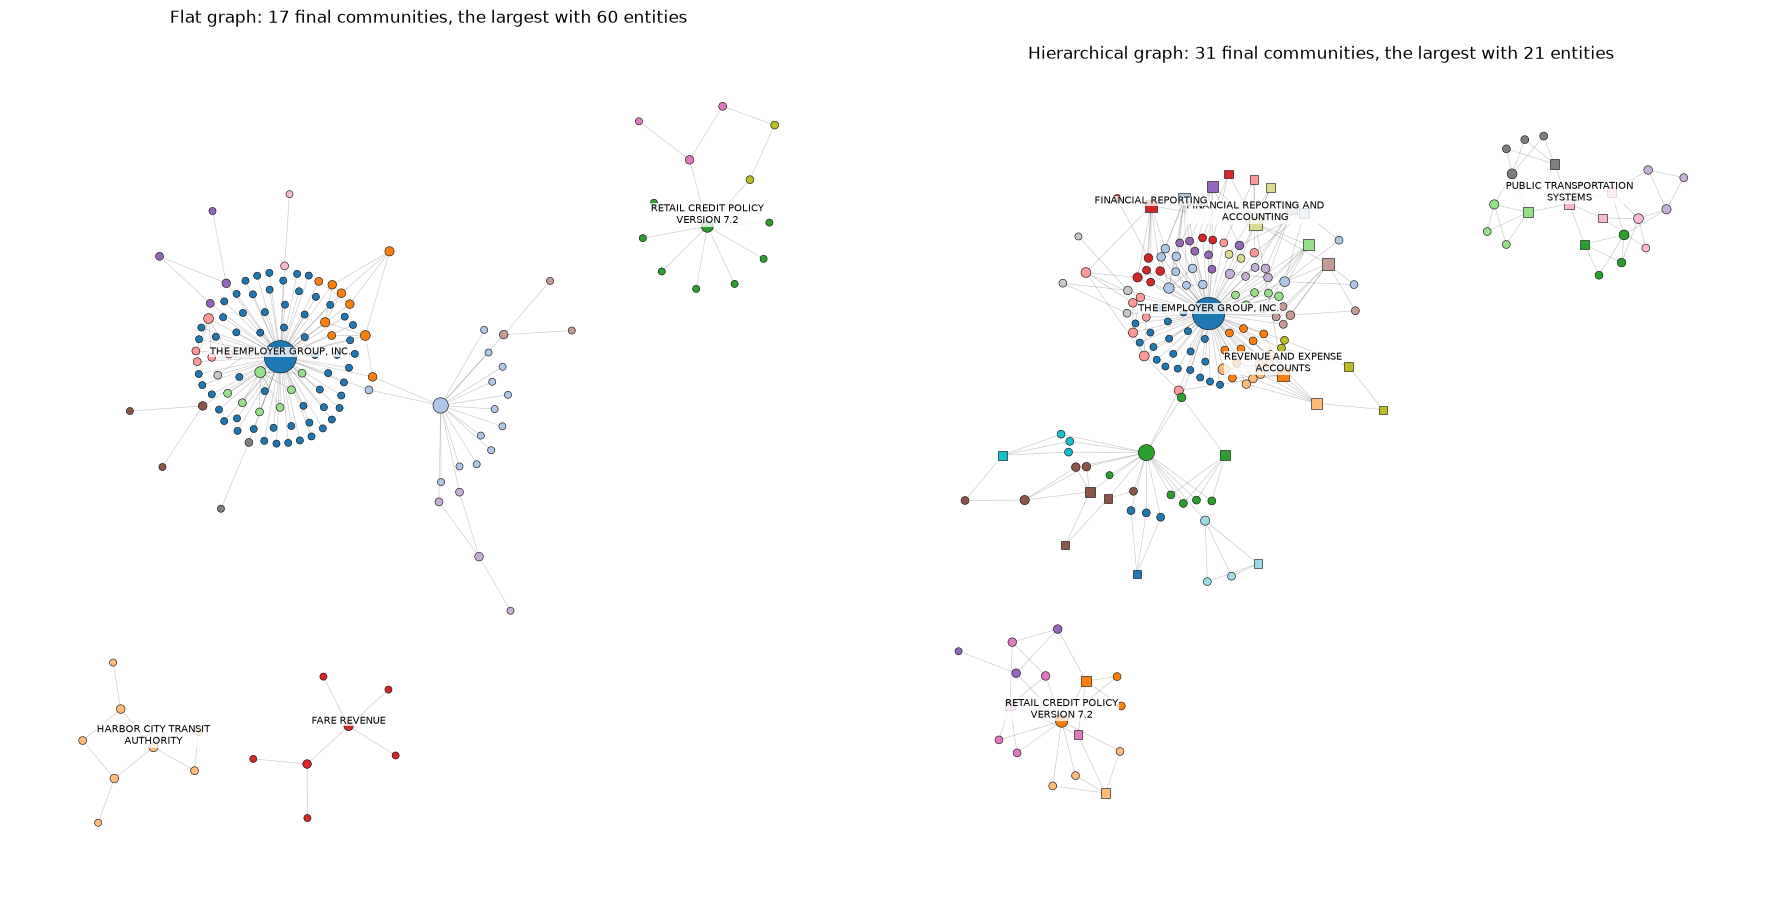

In [13]:
def packed_layout(graph, row_width=3.5, gap=0.15):
    parts = sorted(nx.connected_components(graph), key=len, reverse=True)
    positions, x, y, row_height = {}, 0.0, 0.0, 0.0
    for nodes in parts:
        sub = graph.subgraph(nodes)
        local = nx.kamada_kawai_layout(sub, weight=None) if len(nodes) > 2 else nx.circular_layout(sub)
        points = np.array([local[node] for node in sub.nodes])
        points = points - points.mean(axis=0)
        points = points / (np.abs(points).max() or 1)
        radius = np.sqrt(len(nodes) / len(parts[0])) + 0.08
        if x > 0 and x + 2 * radius > row_width:
            x, y, row_height = 0.0, y - row_height - gap, 0.0
        center = np.array([x + radius, y - radius])
        for node, point in zip(sub.nodes, points):
            positions[node] = center + point * radius
        x += 2 * radius + gap
        row_height = max(row_height, 2 * radius)
    return positions


def draw_communities(ax, g, final, title):
    positions = packed_layout(g)
    palette = plt.get_cmap("tab20").colors
    colors = {c: palette[i % 20] for i, (c, _) in enumerate(Counter(final.values()).most_common())}
    nx.draw_networkx_edges(g, positions, ax=ax, alpha=0.2, width=0.5)
    for shape, nodes in (("o", [n for n in g if g.nodes[n]["layer"] == 0]),
                         ("s", [n for n in g if g.nodes[n]["layer"] > 0])):
        nx.draw_networkx_nodes(g, positions, nodelist=nodes, ax=ax, node_shape=shape,
                               node_color=[colors.get(final.get(n), "lightgray") for n in nodes],
                               node_size=[20 + 6 * g.degree(n) for n in nodes],
                               edgecolors="black", linewidths=0.4)
    hubs = [max(component, key=g.degree) for component in nx.connected_components(g) if len(component) >= 5]
    summaries = sorted((n for n in g if g.nodes[n]["layer"] > 0), key=g.degree, reverse=True)[:3]
    for n in hubs + summaries:
        ax.text(*positions[n], fill(n, 24), fontsize=7, ha="center", va="bottom",
                bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 0.3})
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_axis_off()


fig, axes = plt.subplots(1, 2, figsize=(18, 9))
for ax, g, final, label in ((axes[0], base_graph, flat_final, "Flat graph"),
                            (axes[1], graph, hier_final, "Hierarchical graph")):
    largest = max(Counter(final.values()).values())
    draw_communities(ax, g, final, f"{label}: {len(set(final.values()))} final communities, the largest with {largest} entities")
fig.tight_layout()
plt.show()

The difference is plain. In the flat graph, 60 entities of The Employer Group form one final community: as in notebook 6, Leiden finds nothing to cut in a star, because every entity is attached to the company and to little else. In the hierarchical graph the summary entities give the star an inner structure – LEASE ACCOUNTING, DEBT INSTRUMENTS, TAXATION AND COMPLIANCE and ASSET MANAGEMENT each tie their members together – and Leiden follows it: the same 93 entities fall into 16 final communities, the largest with 21 entities. Notebook 6's GraphRAG split the same company into 2 + 61, then 2 + 59.

This is the effect the paper describes, communities that "reflect both explicit relational patterns and implicit conceptual relationships". On our corpus it is the main benefit of HiIndex: the documents rarely share topics, but each one has many related entities that the text only ever connects to its company.

### Community reports

One report per community of the hierarchical graph, as in GraphRAG: a title, an executive summary, an importance rating from 0 to 10, and a list of findings. `community_text(members)` lists the community's entities, the best-connected first, each with type, layer and description, followed by the relations between them, strongest first. The text is cut at `MAX_REPORT_INPUT` characters, a simple stand-in for GraphRAG's token budget. The prompt tells the model that entities of layer 1 and above are summary entities.

The communities and their reports are cached together under `"communities"`. From here on, the notebook works with the cached communities, so that every report belongs to exactly the entities it was written for.

In [14]:
class CommunityReport(BaseModel):
    title: str = Field(description="A short, specific title that names the community's key entities")
    summary: str = Field(description="An executive summary: what the community is about, how its entities relate, and the key facts")
    rating: float = Field(description="Importance of the community, from 0 to 10")
    findings: list[str] = Field(description="Three to eight key insights, each one or two sentences, with names and figures as stated")


REPORT_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "You write a report about one community of a knowledge graph, for a search index. The "
     "community consists of the entities and relationships below. Entities of layer 1 and above "
     "are summary entities: general concepts that group the entities below them. Write a title "
     "that names the community's key entities, an executive summary, an importance rating from "
     "0 to 10, and three to eight findings. Keep names, figures and dates exactly as stated, and "
     "use only the information given."),
    ("human", "{community}"),
])


def community_text(members):
    sub = graph.subgraph(members)
    lines = ["Entities:"] + [
        f"- {n} ({graph.nodes[n]['type']}, layer {graph.nodes[n]['layer']}): {graph.nodes[n]['description']}"
        for n in sorted(sub.nodes, key=graph.degree, reverse=True)]
    lines += ["", "Relationships:"] + [
        f"- {u} -- {v}: {d['description']}"
        for u, v, d in sorted(sub.edges(data=True), key=lambda e: e[2]["weight"], reverse=True)]
    return "\n".join(lines)[:MAX_REPORT_INPUT]


if "communities" in index:
    print(f"Using cached communities and reports from {CACHE_FILE.name}")
else:
    start = time.time()
    reports = (REPORT_PROMPT | llm.with_structured_output(CommunityReport)).batch(
        [{"community": community_text(c["entities"])} for c in hier_communities],
        config={"max_concurrency": 8},
    )
    index["communities"] = [{**c, "report": r.model_dump()} for c, r in zip(hier_communities, reports)]
    CACHE_FILE.write_text(json.dumps(index, indent=1))
    print(f"{len(reports)} LLM calls in {time.time() - start:.0f} s")

communities = {c["id"]: c for c in index["communities"]}
mixed = sum(1 for c in communities.values() if len({graph.nodes[n]["layer"] for n in c["entities"]}) > 1)
print(f"{len(communities)} communities; {mixed} of them contain entities of more than one layer\n")
for c in sorted(communities.values(), key=lambda c: (c["level"], -len(c["entities"]))):
    if c["level"] == 0:
        print(f"{c['id']:3d}  {len(c['entities']):3d} entities  {c['report']['title']}")

38 LLM calls in 13 s
38 communities; 33 of them contain entities of more than one layer

  6   44 entities  The Employer Group, Inc. Financial Performance and Equity Overview for 2018-2019
  7   28 entities  Novaterra Energy AG's Renewable Energy Assets and Financial Performance in Central Europe
 10   21 entities  Harbor City Transit Authority's Public Transportation Networks and Funding
  9   17 entities  Meridian Bank Retail Credit Policy and Risk Management
  4   13 entities  Accounts Receivable, Current Assets, Employee Benefits, and Cash Flow Items in Financial Reporting
  8   13 entities  Lease Accounting: Capital Leases, Operating Leases, and Long-Term Liabilities of The Employer Group, Inc.
  3   12 entities  Long-Term Debt and Debt Instruments of The Employer Group, Inc.
  1    9 entities  Asset Management and Fixed Asset Categories of The Employer Group, Inc.
  0    7 entities  Taxation and Compliance of The Employer Group, Inc. under Subchapter S Corporation Status
  2    7

Here is the report of the level-0 community that contains Meridian Bank – the community whose GraphRAG report notebook 6 showed:

In [15]:
meridian = max((n for n in base_graph if "Meridian Bank" in base_graph.nodes[n]["organisations"]), key=graph.degree)
focus = next(c for c in communities.values() if c["level"] == 0 and meridian in c["entities"])
report = focus["report"]
lines = [f"### {report['title']}",
         f"*level 0, {len(focus['entities'])} entities, rating {report['rating']:g}*",
         report["summary"], "**Findings**"] + [f"- {finding}" for finding in report["findings"]]
display(Markdown("\n\n".join(lines)))
print("entities:", ", ".join(f"{n} [L{graph.nodes[n]['layer']}]" for n in focus["entities"]))

### Meridian Bank Retail Credit Policy and Risk Management

*level 0, 17 entities, rating 9*

This community centers on Meridian Bank's Retail Credit Policy Version 7.2, which governs the issuance of unsecured personal loans and credit cards to private individuals. The policy, owned and reviewed annually by the Chief Risk Officer, sets eligibility, affordability, credit scoring, and override rules. Key components include the Meridian Retail Score for credit evaluation, debt-service-to-income ratio limits for affordability, and a structured credit decisioning process involving credit officers and team leads. The retail portfolio's performance is monitored monthly using the 90-day delinquency rate metric, with remediation plans required if delinquency exceeds 3% for two consecutive months. The Chief Risk Officer presents such plans to the Risk Committee. The Loan Origination System supports documentation of applications and overrides, ensuring compliance and control.

**Findings**

- Meridian Bank's Retail Credit Policy Version 7.2 applies exclusively to unsecured personal loans and credit cards, excluding mortgages and business loans, and is reviewed annually by the Chief Risk Officer.

- The Meridian Retail Score, ranging from 0 to 1,000, determines application outcomes: below 550 leads to automatic decline, 550-650 requires manual review by credit officers, and above 650 may be approved automatically if other criteria are met.

- Affordability is assessed using the debt-service-to-income ratio (DSTI), capped at 40% for applicants earning above EUR 2,000 monthly net income and 30% for those below, including rent payments as debt service.

- Credit officers may override automatic declines only with written approval from a team lead, limited to 5% of approved applications per quarter, and must document overrides with reason codes in the Loan Origination System.

- Credit decisioning involves a combination of automated scoring and manual reviews to ensure responsible lending and portfolio health.

- The retail portfolio's performance is monitored monthly via the 90-day delinquency rate; if this rate exceeds 3% for two consecutive months, the Chief Risk Officer must present a remediation plan to the Risk Committee within 30 days.

- Credit limits for credit cards are capped at three times the applicant's monthly net income, with an absolute maximum of EUR 15,000, while unsecured personal loans have a maximum amount of EUR 50,000 and term of 84 months.

- The Chief Risk Officer plays a central role in policy ownership, review, and remediation oversight, ensuring alignment with risk management objectives and regulatory compliance.

entities: MERIDIAN BANK [L0], RETAIL CREDIT POLICY VERSION 7.2 [L0], RETAIL PORTFOLIO [L0], RETAIL LENDING [L1], CHIEF RISK OFFICER [L0], UNSECURED PERSONAL LOANS [L0], CREDIT CARDS [L0], DEBT-SERVICE-TO-INCOME RATIO (DSTI) [L0], MERIDIAN RETAIL SCORE [L0], CREDIT OFFICER [L0], TEAM LEAD [L0], LOAN ORIGINATION SYSTEM [L0], CREDIT RISK MANAGEMENT [L1], 90-DAY DELINQUENCY RATE [L0], RISK COMMITTEE [L0], CREDIT DECISIONING PROCESS [L1], CREDIT LENDING AND RISK MANAGEMENT [L2]


The report is accurate. Notebook 6's GraphRAG report on the same community claimed that team leads "have override limits capped at 5 percent of approved applications per quarter"; this one states the rule correctly – an override needs a team lead's written approval, and overrides may not exceed 5 percent of the approved applications in a quarter. That is one report from one run, not a guarantee: reports remain summaries of summaries, which is why the context also carries the source chunks. The list of entities shows what 33 of the 38 communities have in common: base entities (L0) together with the summary entities that group them (L1, L2).

## Step 5 – HiRetrieval

### The entity index

All entities of all layers go into one Chroma collection, embedded as `NAME: description`, as in HiRAG's code. This is the collapsed tree of notebook 5 in graph form: a broad question can match a summary entity, a detailed one a base entity. The entity names serve as Chroma ids.

`communities_of` maps every entity to the communities it belongs to, up to `COMMUNITY_LEVEL`. An entity is in at most one community per level: its community at level 0, the sub-community of that at level 1, and so on.

In [16]:
entity_store = Chroma(
    collection_name="hirag_entities",
    embedding_function=embeddings,
    collection_metadata={"hnsw:space": "cosine"},
)
entity_store.reset_collection()
entity_store.add_documents(
    [Document(page_content=f"{n}: {d['description']}", metadata={"name": n, "layer": d["layer"]})
     for n, d in graph.nodes(data=True)],
    ids=list(graph.nodes),
)

communities_of = {n: [] for n in graph}
for c in communities.values():
    if c["level"] <= COMMUNITY_LEVEL:
        for n in c["entities"]:
            communities_of[n].append(c["id"])
print(f"Indexed {graph.number_of_nodes()} entities; "
      f"{sum(1 for ids in communities_of.values() if ids)} of them belong to a community")

Indexed 175 entities; 175 of them belong to a community


### The three levels

`hi_retrieve(question)` is the paper's Algorithm 2:

1. **Local** (equation 12). All entities are ranked by similarity to the question with `similarity_search(question, k=<all entities>)`, which returns the documents in order. (The variant `with_relevance_scores` would warn here, because some cosine similarities are negative.) The first `TOP_N` are the local entities.
2. **Global** (equation 13). Every community that contains a local entity is a candidate. They are ranked as in HiRAG's code, by how many local entities they contain and then by the rating of their report, and taken in that order until `REPORT_BUDGET` characters of reports are used.
3. **Bridge** (equations 14–16). From every selected community we take its `TOP_M` entities ranked highest for the question: the *key entities*, kept in order. Consecutive key entities are joined by a shortest path in the hierarchical graph (`nx.shortest_path`, counting hops). When two of them are not connected – different documents of our corpus often aren't – the path is interrupted and a new segment starts; HiRAG's code just appends the next key entity. The bridge consists of every relation between two entities on the path, that is, the edges of the subgraph that the path's entities induce. They are sorted as in HiRAG's code – the edges between the best-connected entities first, then by weight – and at most `MAX_BRIDGE` are kept.
4. **Sources.** The chunks the local entities come from, the most frequent first. They are not in the paper, but HiRAG's code adds them as "Source Documents". Notebook 6 showed why they help: reports, as summaries of summaries, can drift from the text.

In [17]:
def report_text(community_id):
    report = communities[community_id]["report"]
    return f"{report['title']}\n{report['summary']}\n" + "\n".join(f"- {f}" for f in report["findings"])


def hi_retrieve(question):
    ranked = [doc.metadata["name"] for doc in entity_store.similarity_search(question, k=graph.number_of_nodes())]
    position = {name: i for i, name in enumerate(ranked)}
    local = ranked[:TOP_N]

    counts = Counter(c for n in local for c in communities_of[n])
    selected, used = [], 0
    for c in sorted(counts, key=lambda c: (counts[c], communities[c]["report"]["rating"]), reverse=True):
        used += len(report_text(c))
        if used > REPORT_BUDGET:
            break
        selected.append(c)

    key_entities = list(dict.fromkeys(
        n for c in selected for n in sorted(communities[c]["entities"], key=position.get)[:TOP_M]))
    segments = []
    for n in key_entities:
        if segments and nx.has_path(graph, segments[-1][-1], n):
            segments[-1] += nx.shortest_path(graph, segments[-1][-1], n)[1:]
        else:
            segments.append([n])
    path = {n for segment in segments for n in segment}
    bridge = sorted(graph.subgraph(path).edges(data=True),
                    key=lambda e: (graph.degree(e[0]) + graph.degree(e[1]), e[2]["weight"]),
                    reverse=True)[:MAX_BRIDGE]

    sources = [c for c, _ in Counter(c for n in local for c in graph.nodes[n]["chunks"]).most_common(TOP_SOURCES)]
    return {"local": local, "communities": selected, "counts": counts, "key_entities": key_entities,
            "segments": segments, "bridge": bridge, "sources": sources}

### The context and the prompt

`build_context` lays out the four parts in the order and under the headings of HiRAG's code: Backgrounds (the community reports), Reasoning Path (the bridge), Detail Entity Information (the local entities) and Source Documents. Every item gets an id that starts with its part's letter – `[R1]`, `[B1]`, `[E1]`, `[S1]` – so the citations in an answer show which level it drew on; `cited` counts them. `bridge=False` leaves out the reasoning path, which is the paper's "w/o Bridge" ablation.

`show_retrieval` prints what was retrieved: the first ten local entities with their layer, the selected communities with their level, size and number of local entities, the key entities, and the path segments.

In [18]:
def build_context(r, bridge=True):
    parts = ["-----Backgrounds-----"]
    parts += [f"[R{i}] {report_text(c)}" for i, c in enumerate(r["communities"], 1)]
    if bridge:
        parts += ["", "-----Reasoning Path-----"]
        parts += [f"[B{i}] {u} -- {v}: {d['description']}" for i, (u, v, d) in enumerate(r["bridge"], 1)]
    parts += ["", "-----Detail Entity Information-----"]
    parts += [f"[E{i}] {n} (layer {graph.nodes[n]['layer']}): {graph.nodes[n]['description']}"
              for i, n in enumerate(r["local"], 1)]
    parts += ["", "-----Source Documents-----"]
    parts += [f"[S{i}] ({chunk_by_id[c].metadata['title']})\n{chunk_by_id[c].page_content}"
              for i, c in enumerate(r["sources"], 1)]
    return "\n".join(parts)


ANSWER_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "You answer questions using ONLY the context below. If the context does not contain the "
     "answer, say you don't know. The context has four parts: Backgrounds are reports about "
     "communities of related entities [R], the Reasoning Path lists relations that connect the "
     "key entities of these communities [B], Detail Entity Information describes the entities "
     "closest to the question [E], and Source Documents are excerpts from the original text [S]. "
     "Cite the items you used like [R1], [B2], [E3], [S1].\n\n"
     "Context:\n{context}"),
    ("human", "{question}"),
])
answer_chain = ANSWER_PROMPT | llm | StrOutputParser()


def cited(answer):
    items = set(re.findall(r"\b([RBES]\d+)\b", answer))
    counts = Counter(item[0] for item in items)
    return ", ".join(f"{name} {counts[letter]}" for letter, name in
                     (("R", "reports"), ("B", "bridge"), ("E", "entities"), ("S", "sources")))


def show_retrieval(r):
    print("local entities: " + ", ".join(f"{n} [L{graph.nodes[n]['layer']}]" for n in r["local"][:10]) + ", ...")
    print(f"communities ({len(r['communities'])}):")
    for c in r["communities"]:
        community = communities[c]
        print(f"  {c:3d}  level {community['level']}, {len(community['entities']):2d} entities, "
              f"{r['counts'][c]:2d} local  {community['report']['title']}")
    print(f"key entities ({len(r['key_entities'])}): {', '.join(r['key_entities'])}")
    print(f"path, in {len(r['segments'])} segment(s):")
    for segment in r["segments"]:
        print(fill(" -> ".join(segment), 110, initial_indent="  ", subsequent_indent="      "))
    print(f"bridge: {len(r['bridge'])} relations; sources: {', '.join(r['sources'])}; "
          f"context: {len(build_context(r)):,} characters")

### One question, step by step

Notebook 5's topic question, about one company's obligations, whose answer is spread over four notes and two tables. Below the printout, the path is drawn: the entities on it, coloured by organisation (summary entities grey and square), with the key entities outlined in black and the bridge relations drawn darker than the other edges between path entities.

local entities: LEASE OBLIGATIONS [L0], LONG-TERM DEBT [L0], TOTAL LIABILITIES [L0], THE EMPLOYER GROUP, INC. [L0], TOTAL LIABILITIES AND STOCKHOLDER'S EQUITY [L0], OPERATING LEASE [L0], EMPLOYEES [L0], NON-CANCELABLE OPERATING LEASE [L0], TOTAL CURRENT LIABILITIES [L0], LEASED OFFICE EQUIPMENT [L0], ...
communities (10):
    8  level 0, 13 entities,  6 local  Lease Accounting: Capital Leases, Operating Leases, and Long-Term Liabilities of The Employer Group, Inc.
    6  level 0, 44 entities,  6 local  The Employer Group, Inc. Financial Performance and Equity Overview for 2018-2019
   28  level 1,  6 entities,  4 local  Lease Accounting and Lease Obligations for Office Facilities and Capital Leased Copiers
    2  level 0,  7 entities,  4 local  Financial Reporting and Balance Sheet Items of The Employer Group, Inc. for 2018-2019
   16  level 1, 21 entities,  3 local  The Employer Group, Inc. Financial Overview and Operations
   19  level 1,  9 entities,  2 local  The Employer Group, In

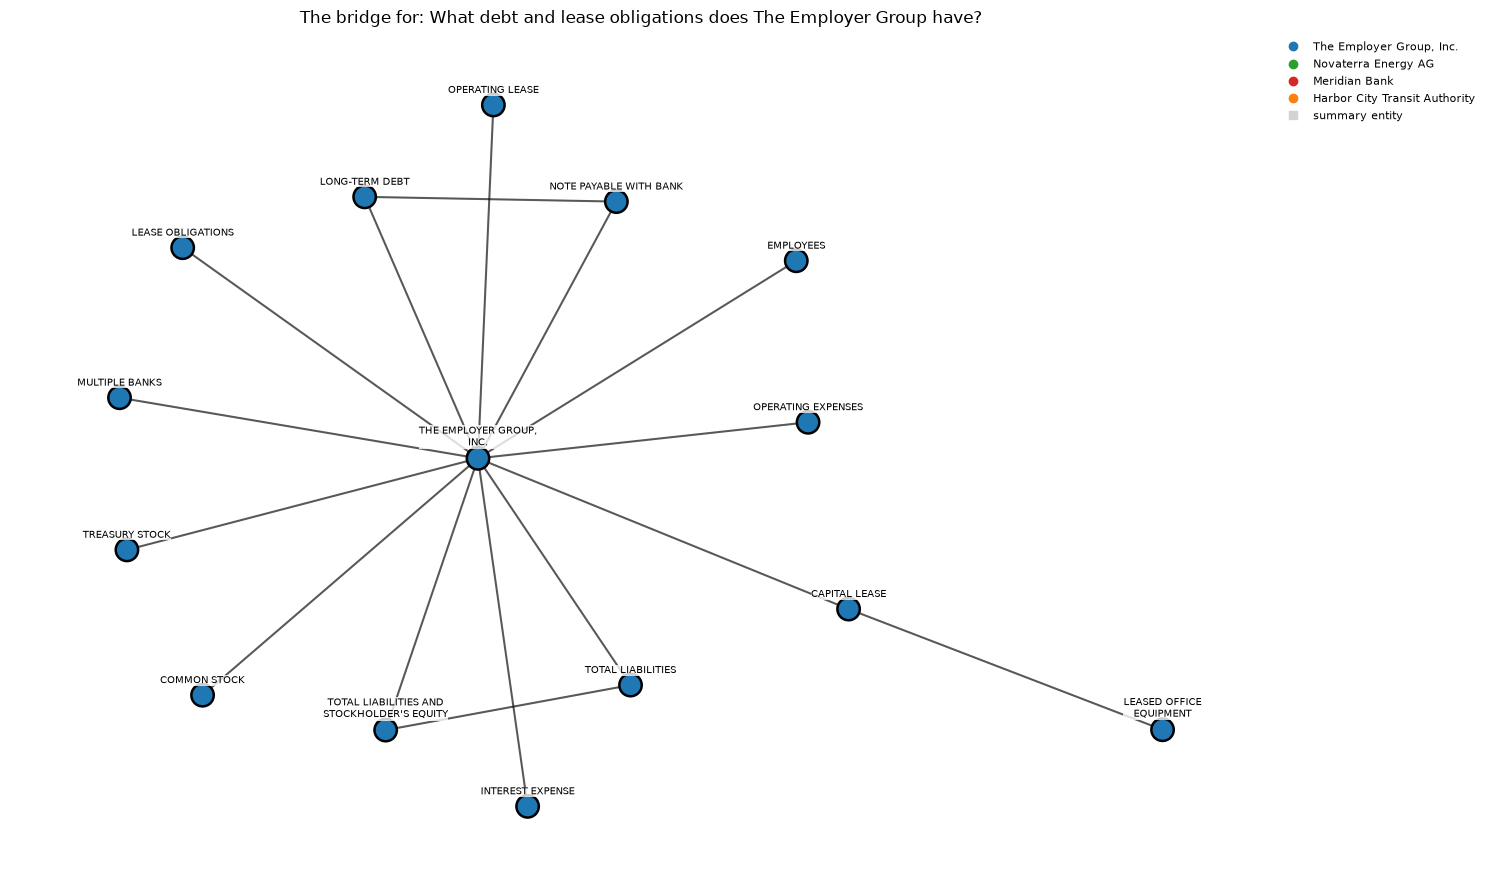

In [19]:
ORGANISATION_COLORS = {"The Employer Group, Inc.": "tab:blue", "Novaterra Energy AG": "tab:green",
                       "Meridian Bank": "tab:red", "Harbor City Transit Authority": "tab:orange"}


def node_color(n):
    organisations = graph.nodes[n]["organisations"]
    if graph.nodes[n]["layer"] > 0:
        return "lightgray"
    return ORGANISATION_COLORS[organisations[0]] if len(organisations) == 1 else "tab:purple"


def draw_path(r, title):
    sub = graph.subgraph({n for segment in r["segments"] for n in segment})
    positions = packed_layout(sub, row_width=4.5)
    fig, ax = plt.subplots(figsize=(15, 9))
    nx.draw_networkx_edges(sub, positions, ax=ax, alpha=0.15)
    nx.draw_networkx_edges(sub, positions, edgelist=[(u, v) for u, v, _ in r["bridge"]], ax=ax, width=1.5, alpha=0.6)
    for shape, nodes in (("o", [n for n in sub if sub.nodes[n]["layer"] == 0]),
                         ("s", [n for n in sub if sub.nodes[n]["layer"] > 0])):
        nx.draw_networkx_nodes(sub, positions, nodelist=nodes, ax=ax, node_shape=shape, node_size=260,
                               node_color=[node_color(n) for n in nodes],
                               edgecolors=["black" if n in r["key_entities"] else "white" for n in nodes],
                               linewidths=1.8)
    for n in sub:
        ax.annotate(fill(n, 22), positions[n], xytext=(0, 7), textcoords="offset points", fontsize=7,
                    ha="center", va="bottom", bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 0.2})
    handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=o) for o, c in ORGANISATION_COLORS.items()]
    handles.append(plt.Line2D([], [], marker="s", ls="", color="lightgray", label="summary entity"))
    ax.legend(handles=handles, fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
    ax.set_title(title)
    ax.set_axis_off()
    fig.tight_layout()
    plt.show()


question = "What debt and lease obligations does The Employer Group have?"
r = hi_retrieve(question)
show_retrieval(r)
draw_path(r, f"The bridge for: {question}")

Every part of the retrieval is visible here:

- The local entities are the lease and debt items, plus the company itself and its balance-sheet totals.
- Ten communities fit into the budget, all of them about the Employer Group: the lease accounting community first (six local entities), followed by the company's financial overview, its balance sheet, its capital leases and its long-term debt, among others.
- Up to two key entities per community, fifteen after removing duplicates.
- The path is a single segment, and between almost every pair of key entities it runs through THE EMPLOYER GROUP, INC. In a star-shaped graph, the shortest path between two entities of the same company leads through the company. A summary entity would often be just as short – member, summary entity, member – but `nx.shortest_path` returns the first shortest path it finds. The drawing shows the result: the bridge is a fan of the company's relations to its key entities.

These relations are true and relevant, but they mostly repeat what the descriptions of the local entities already say. In the paper's graphs, with thousands of entities and many documents per topic, the shortest path between two communities is far more likely to pass through the summary entities that link them.

## Step 6 – Run it

Four questions at different scales:

1. a **detail** – who approves an override at Meridian Bank, the question of notebooks 3 and 6;
2. a **topic** within one document – The Employer Group's debt and leases, as in notebook 5 and above;
3. the **whole corpus** – notebook 6's global question, which GraphRAG answered with a map-reduce over all community reports;
4. an **entity with its context** – how Novaterra is doing and what could change that, in the spirit of the paper's example question "Please introduce Amazon".

For each question: the retrieval, the answer, and which levels the answer cites.

In [20]:
QUESTIONS = [
    "Who has to approve an override of an automatically declined loan at Meridian Bank?",
    "What debt and lease obligations does The Employer Group have?",
    "What are the main topics of these documents, and which organisations do they describe?",
    "How is Novaterra Energy doing financially, and what could put that at risk?",
]

retrievals, answers = {}, {}
for question in QUESTIONS:
    print("=" * 110 + f"\nQuestion: {question}\n")
    retrievals[question] = r = hi_retrieve(question)
    show_retrieval(r)
    answers[question] = answer = answer_chain.invoke({"context": build_context(r), "question": question})
    display(Markdown(answer))
    print(f"cited: {cited(answer)}\n")

Question: Who has to approve an override of an automatically declined loan at Meridian Bank?



local entities: TEAM LEAD [L0], CREDIT OFFICER [L0], LOAN ORIGINATION SYSTEM [L0], CHIEF RISK OFFICER [L0], UNSECURED PERSONAL LOANS [L0], CREDIT CARDS [L0], MERIDIAN RETAIL SCORE [L0], MERIDIAN BANK [L0], RETAIL CREDIT POLICY VERSION 7.2 [L0], RETAIL PORTFOLIO [L0], ...
communities (9):
    9  level 0, 17 entities, 15 local  Meridian Bank Retail Credit Policy and Risk Management
   30  level 1,  6 entities,  6 local  Meridian Bank's Retail Lending: Unsecured Personal Loans and Credit Cards
   32  level 1,  4 entities,  4 local  Credit Decisioning Process at Meridian Bank: Roles, Overrides, and Documentation
   29  level 1,  3 entities,  3 local  90-Day Delinquency Rate, Chief Risk Officer, and Risk Committee at Meridian Bank
    5  level 0,  4 entities,  3 local  The Employer Group, Inc. Credit Facilities and Interest Rates
   31  level 1,  4 entities,  2 local  Meridian Bank Retail Credit Policy, Credit Risk Management, and Scoring Metrics
    6  level 0, 44 entities,  1 local  The E

At Meridian Bank, an override of an automatically declined loan by a credit officer requires written approval from a team lead. This is specified in the Retail Credit Policy Version 7.2, which states that credit officers may override automatic declines only with written approval from a team lead, and such overrides must be documented with reason codes in the loan origination system [R1], [R3], [E1], [E2], [S1].

cited: reports 2, bridge 0, entities 2, sources 1

Question: What debt and lease obligations does The Employer Group have?

local entities: LEASE OBLIGATIONS [L0], LONG-TERM DEBT [L0], TOTAL LIABILITIES [L0], THE EMPLOYER GROUP, INC. [L0], TOTAL LIABILITIES AND STOCKHOLDER'S EQUITY [L0], OPERATING LEASE [L0], EMPLOYEES [L0], NON-CANCELABLE OPERATING LEASE [L0], TOTAL CURRENT LIABILITIES [L0], LEASED OFFICE EQUIPMENT [L0], ...
communities (10):
    8  level 0, 13 entities,  6 local  Lease Accounting: Capital Leases, Operating Leases, and Long-Term Liabilities of The Employer Group, Inc.
    6  level 0, 44 entities,  6 local  The Employer Group, Inc. Financial Performance and Equity Overview for 2018-2019
   28  level 1,  6 entities,  4 local  Lease Accounting and Lease Obligations for Office Facilities and Capital Leased Copiers
    2  level 0,  7 entities,  4 local  Financial Reporting and Balance Sheet Items of The Employer Group, Inc. for 2018-2019
   16  level 1, 21 entities,  3 loc

The Employer Group, Inc. has the following debt and lease obligations:

1. Long-Term Debt:
- Total long-term debt as of December 31, 2019 was $287,002 after deducting current maturities of $352,632 from total notes payable of $639,634.
- Future maturities of long-term debt at December 31, 2019 are:
  - $352,632 due in 2020
  - $247,798 due in 2021
  - $22,564 due in 2022
  - $11,007 due in 2023
  - $5,633 due in 2024
  - Totaling $639,634
- The long-term debt includes various notes payable to financial institutions and a bank, some bearing interest rates such as 3.582% and 2.94%, and others zero interest, collateralized by vehicles and company assets.
- Principal payments on long-term debt were $348,408 in 2019.

2. Capital Leases:
- The Employer Group leases certain office equipment (copiers) under capital lease agreements.
- Capitalized cost of leased office equipment was $48,345 at December 31, 2019.
- Accumulated depreciation on leased equipment was $3,223 at December 31, 2019.
- Future minimum lease payments under the capital lease total $49,866, with annual payments of $11,081 from 2020 through 2023 and $5,542 in 2024.
- Present value of future minimum lease payments is $44,085 as of December 31, 2019.
- Lease payments made on lease obligations were $16,185 in 2019.

3. Operating Leases:
- The Employer Group leases office facilities under a non-cancelable operating lease expiring August 31, 2024.
- Future minimum rental commitments under the operating lease total $1,568,000 as of December 31, 2019, payable as $336,000 annually from 2020 through 2023 and $224,000 in 2024.
- Rent expense under operating leases was $216,722 for the year ended December 31, 2019.

These obligations reflect the company's financial commitments related to debt financing and leasing of office equipment and facilities [R1][R3][R8][R9][E1][E2][E10][E11][E16][S1][S2].

cited: reports 4, bridge 0, entities 5, sources 2

Question: What are the main topics of these documents, and which organisations do they describe?

local entities: GEOGRAPHIC LOCATION [L1], TAXATION AND COMPLIANCE [L1], PUBLIC TRANSPORTATION SYSTEMS [L2], FINANCIAL REPORTING AND ACCOUNTING [L2], PUBLIC TRANSPORTATION NETWORKS [L1], FARE STRUCTURE AND POLICY [L1], FINANCIAL REPORTING [L1], THE EMPLOYER GROUP, INC. [L0], PUBLIC TRANSPORT FUNDING MODELS [L1], FINANCIAL INSTRUMENTS AND RISK MANAGEMENT [L2], ...
communities (9):
    7  level 0, 28 entities,  4 local  Novaterra Energy AG's Renewable Energy Assets and Financial Performance in Central Europe
   10  level 0, 21 entities,  4 local  Harbor City Transit Authority's Public Transportation Networks and Funding
    9  level 0, 17 entities,  2 local  Meridian Bank Retail Credit Policy and Risk Management
   34  level 1,  5 entities,  2 local  Harbor City Tram Network and Regenerative Braking Technology
    4  level 0, 13 entities,  2 

The main topics of the documents and the organizations they describe are:

1. Novaterra Energy AG: The documents cover Novaterra Energy AG's transition from coal-fired power generation to renewable energy, focusing on wind farms and battery storage assets in Central Europe. They detail the company's financial performance in 2025, including revenue, EBITDA, net income, capital expenditures, operational risks, and electricity distribution to households and industrial customers [R1].

2. Harbor City Transit Authority (HCTA): The documents describe HCTA's public transportation networks in Harbor City, including bus, tram, and ferry services. They discuss operating budgets, funding sources, fare policies, network performance metrics such as on-time performance, adoption of regenerative braking technology in trams, and planned improvements like dedicated bus lanes [R2, R4].

3. Meridian Bank: The documents focus on Meridian Bank's Retail Credit Policy Version 7.2, which governs unsecured personal loans and credit cards. Topics include credit scoring, affordability assessments, override rules, portfolio performance monitoring, and the loan origination system used for documentation and compliance [R3].

4. The Employer Group, Inc.: The documents present detailed financial statements and reporting for The Employer Group, Inc. for the years ended December 31, 2019 and 2018. They cover financial performance metrics such as revenues, expenses, net income, assets, liabilities, stockholder's equity, employee benefits and compensation policies, revenue recognition standards followed, fixed assets, debt instruments, and risk management [R5, R6, R7, R8, R9; E8].

In summary, the documents describe four organizations: Novaterra Energy AG (renewable energy utility), Harbor City Transit Authority (public transportation operator), Meridian Bank (retail credit provider), and The Employer Group, Inc. (professional employer organization), each with their respective operational, financial, and policy details.

cited: reports 9, bridge 0, entities 1, sources 0

Question: How is Novaterra Energy doing financially, and what could put that at risk?

local entities: LOWER WHOLESALE POWER PRICES [L0], LEVERAGE RATIO [L0], NET DEBT [L0], DIVIDEND [L0], EBITDA [L0], LONG-TERM SUPPLY CONTRACTS [L0], ONSHORE WIND PORTFOLIO [L0], NET INCOME [L0], REVENUE [L0], NOVATERRA ENERGY AG [L0], ...
communities (10):
    7  level 0, 28 entities, 17 local  Novaterra Energy AG's Renewable Energy Assets and Financial Performance in Central Europe
   22  level 1,  8 entities,  7 local  Novaterra Energy AG's Financial Performance and Coal Transition in 2025
   24  level 1,  4 entities,  3 local  Operational Risks in Energy Sector: Rising Turbine Costs, Lower Wholesale Power Prices, and Delays in Permitting
   25  level 1,  6 entities,  3 local  Kessel Ridge Wind Farm and Battery Facility in Renewable Energy Generation
   21  level 1,  4 entities,  3 local  Novaterra Energy AG's Geographic Operations in Austria and Ce

Novaterra Energy AG is performing strongly financially as of 2025. The company reported revenue of EUR 4.2 billion, which is a 9% increase from the prior year, with an EBITDA of EUR 910 million and net income of EUR 312 million. Its net debt decreased to EUR 2.1 billion, improving the leverage ratio from 2.8x to 2.3x, and the company aims to maintain leverage below 3.0x during its current investment cycle. The board proposed an increased dividend of EUR 1.40 per share, up from EUR 1.25, reflecting strong profitability. The company also secured new long-term supply contracts with industrial customers, contributing to revenue growth. For 2026, Novaterra expects revenue between EUR 4.4 and 4.6 billion and plans capital expenditures of EUR 1.1 billion focused mainly on new wind capacity and grid upgrades [R1, R2, R8, E4, E6, E9, E10].

However, Novaterra Energy faces operational risks that could threaten its financial performance. The main risks identified for 2026 include lower wholesale power prices, which could reduce revenue and profitability; rising turbine costs, which could increase capital expenditures and negatively impact project economics; and delays in permitting, which could cause project timeline extensions and increased costs due to regulatory hurdles. These risks collectively pose challenges to the company's project timelines, costs, and financial outcomes [R3, E1, E13, E18, B15, B17].

cited: reports 4, bridge 2, entities 7, sources 0



All four answers are right, and the citations show where they came from:

1. **Detail.** The override question is answered from the Meridian community reports, the entities TEAM LEAD and CREDIT OFFICER and the policy text: a team lead's written approval, documented in the loan origination system. The retrieval also brought in four communities of the Employer Group, because its revolving credit loan and its bank resemble the question; they cost context but did no harm.
2. **Topic.** The debt and lease answer has the long-term debt with its maturities and interest rates, the capital lease with its payment schedule and present value, and the operating lease with its rental commitments – the scope of notebook 5's collapsed-tree answer, from reports, entities and two source chunks.
3. **Whole corpus.** Here the summary entities pay off in retrieval: nine of the first ten local entities are summary entities (GEOGRAPHIC LOCATION, PUBLIC TRANSPORTATION SYSTEMS, FINANCIAL REPORTING AND ACCOUNTING, …), because a question about topics matches concepts better than facts. Their communities cover all four organisations, and the answer, built from nine reports, describes all four – what notebook 6 needed a map-reduce over every community report for. Two caveats: the budget matters (while developing this notebook, a version that kept only the top four communities answered about the Employer Group alone), and the answer lists what each document is about rather than relating them.
4. **Entity in context.** The Novaterra answer combines the figures – revenue, EBITDA, net debt, leverage, dividend and the 2026 outlook – with the risks, and cites two bridge relations for the risks. Its path shows a weakness, though: from NOVATERRA ENERGY AG it walks through NET INCOME into the Employer Group's notes payable, because four of the selected communities belong to the Employer Group. The generic entity that the base graph shared now leads the bridge into the wrong company; the LLM simply ignores those relations.

Across the four answers the bridge was cited twice, both times in the last one. Reports and entities carried the answers.

### Without the bridge

The paper's ablation "w/o Bridge" answers from the same context minus the reasoning path. Here it is for the last question; the answer with the bridge is the one above.

In [21]:
question = QUESTIONS[-1]
r = retrievals[question]
without = answer_chain.invoke({"context": build_context(r, bridge=False), "question": question})
display(Markdown(without))
print(f"without the bridge: {len(without):,} characters, cited: {cited(without)}")
print(f"with the bridge:    {len(answers[question]):,} characters, cited: {cited(answers[question])}")

Novaterra Energy AG is performing strongly financially as of 2025. The company reported revenue of EUR 4.2 billion, which is a 9% increase from the prior year, with EBITDA reaching EUR 910 million and net income of EUR 312 million. The board proposed a dividend increase to EUR 1.40 per share, up from EUR 1.25. The company's net debt decreased to EUR 2.1 billion, improving its leverage ratio from 2.8x to 2.3x, with a target to maintain leverage below 3.0x during the current investment cycle. Revenue growth was driven mainly by higher output from its onshore wind portfolio and new long-term supply contracts with industrial customers. The company distributes electricity to roughly 1.8 million households in Central Europe and has completed its transition away from coal by selling its last two coal-fired plants in March 2025, reinvesting proceeds into wind and battery storage assets [R1][R2][E3][E4][E5][E6][E7][E9][E10][E12].

However, Novaterra Energy AG faces operational risks that could threaten its financial performance in 2026. These risks include potential delays in permitting, rising turbine costs, and lower wholesale power prices. Delays in permitting could extend project timelines and increase costs, rising turbine costs could increase capital expenditure and negatively impact project economics, and lower wholesale power prices could reduce revenue and profitability [R3][E1][E13][E18][S2].

In summary, Novaterra Energy AG is financially healthy with strong revenue growth, profitability, and improved leverage, but its future financial outcomes could be at risk due to operational challenges such as regulatory delays, cost increases, and market price declines.

without the bridge: 1,689 characters, cited: reports 3, bridge 0, entities 11, sources 1
with the bridge:    1,420 characters, cited: reports 4, bridge 2, entities 7, sources 0


Without the reasoning path the answer is just as correct and complete. It even adds two details (the 1.8 million households and the sale of the last coal plants) and leaves out another (the 2026 outlook). Differences like these are the normal variation between two LLM answers, not an effect of the bridge. The paper measured the bridge with an LLM judge over hundreds of questions on large corpora: the full method won 53 to 58 percent of the comparisons against the version without bridge – a real but modest effect, which one question on four short documents cannot show.

## What HiRAG adds – and what it costs

In [22]:
calls = {
    "entity and relation extraction": 2 * len(index["extraction"]),
    "summary entities": sum(sum(1 for c in layer["clusters"] if len(c) > 1) for layer in index["layers"]),
    "community reports": len(index["communities"]),
}
for stage, count in calls.items():
    print(f"{stage:32} {count:3d} LLM calls")
print(f"{'total':32} {sum(calls.values()):3d}")

entity and relation extraction    38 LLM calls
summary entities                   9 LLM calls
community reports                 38 LLM calls
total                             85


- **What it adds.** Summary entities give the knowledge graph a layer of concepts above the facts. On our documents this mattered most for the communities: Leiden could finally split the Employer Group's star into topics, and 33 of the 38 communities combine facts with the concepts that group them. In retrieval, summary entities let a broad question match concepts instead of scattered facts, and the three-level context gave correct answers at every scale, from one approval rule to the whole corpus, without a map-reduce.
- **What it costs.** 85 LLM calls to build the index, against 65 for notebook 6's GraphRAG (18 extractions, 23 description merges, 24 reports) and 12 for notebook 5's RAPTOR tree. Extraction and reports dominate; the summary layers took only 9 calls here. On the paper's corpora, where the summary layers are much larger, HiRAG's indexing used two to three and a half times GraphRAG's tokens. Retrieval needs no LLM call, but every answer reads 30,000 to 40,000 characters of context (8,000 to 10,000 tokens) – far more than the four chunks of notebook 1.
- **What to watch.** The summary layers depend on details the paper leaves open: the meta types, the style of the descriptions and the output format each decided, during development, whether a layer added concepts or merely renamed entities. On a small corpus the upper layers are clustered in BIC's degenerate regime (notebook 5c). Summary entities connect documents only if their entities share topics; ours did not, and the cross-document links that exist come from generic entities merged by name, which the bridge then follows into the wrong company. In a star-shaped graph, the bridge mostly restates the hub's relations.
- **When to use it.** For large collections from one domain, where many documents talk about overlapping concepts and the questions need both details and overview – the setting of the paper's experiments, with corpora of millions of tokens. For a handful of documents about unrelated organisations, the community reports and the local entities do most of the work, and for single facts plain vector RAG with a reranker (notebook 3) remains cheaper and as good.

## Things to try

1. **The reference meta types.** Set `META_TYPES` to HiRAG's own list – `["organization", "person", "location", "event", "product", "technology", "industry", "mathematics", "social sciences"]` – delete `hirag_index.json` and rebuild. How many summary entities are just the names of the companies?
2. **The reference output format.** Replace `ClusterSummary` by the format of HiRAG's prompt – a list of summary entities and, separately, a list of links from members to summary entities – and adapt `valid_summaries`. How often does the top layer turn into one "summary" per entity?
3. **Without HiIndex.** The paper's other ablation. At the start of step 4, set `graph = base_graph` and `CACHE_FILE = Path("hirag_flat.json")` and run `index.pop("communities")`, so that communities, reports and the entity index are built from the flat graph and saved separately. Then ask the four questions again. Which answers change?
4. **More key entities.** Set `TOP_M = 10`, the value of HiRAG's code. How long do the paths get, and does any answer cite more of the bridge?
5. **A tighter budget.** With `REPORT_BUDGET = 5000` only the top few communities fit. Does the corpus question still cover all four organisations?
6. **Ask GraphRAG.** Run the debt question through notebook 6's local search and the Novaterra question through its global search, and compare the answers and the sizes of the contexts.
7. **Run it locally.** Set `RAG_LLM="ollama:mistral-small3.2:24b"` before starting Jupyter and `EMBEDDING_MODEL = "ollama:embeddinggemma:300m"`, delete `hirag_index.json` and rebuild. Expect well over an hour on a laptop, and watch whether the summary step still returns usable structured output.
8. **Documents that share topics.** Our four organisations have little in common, which is why the summary layers stayed inside them. Write a short credit policy for a second bank, or a second utility's annual report, add it to `data/` and `DOCUMENTS`, rebuild, and look for summary entities that join documents – and for the five unconnected pairs of similar entities.